### Practice 1 - Notebook 2

# Applications of Clustering and PCA — Exercise 1

## Anomaly Detection: Changing the Threshold Rate in `flag_top` to 5%

In this exercise, we modify the anomaly flagging threshold from 2% (`rate=0.02`) to 5% (`rate=0.05`), inspecting the top 5% of anomaly scores across K-Means, Gaussian Mixture Models, and PCA.

**Question:** Change `rate` in `flag_top` to `0.05`. Which tools start flagging normal points?

## Cell 1 — Import Required Libraries

Import NumPy, Pandas, Matplotlib, and clustering/anomaly tools from scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

## Cell 2 — Generate the Toy Anomaly Dataset

Recreate the exact same dataset of normal clustered points along a line plus 6 planted anomalies.

In [ ]:
rng = np.random.default_rng(42)
along = np.array([1.0, 0.55]) / np.linalg.norm([1.0, 0.55])
across = np.array([-along[1], along[0]])

def stretched_group(center, n):
    return center + np.outer(rng.normal(0, 0.95, n), along) + np.outer(rng.normal(0, 0.28, n), across)

normal_points = np.vstack([stretched_group(-4.0 * along, 170), stretched_group(4.0 * along, 170)])
planted = np.array([
    [-1.5, 2.6], [2.2, -2.4], [-4.8, 1.2], [5.0, -0.4],
    [0.0, 0.0],
    [8.6, 4.8],])

X_anom = np.vstack([normal_points, planted])
is_planted = np.r_[np.zeros(len(normal_points), bool), np.ones(len(planted), bool)]

print("samples:", X_anom.shape, " planted anomalies:", is_planted.sum())

samples: (346, 2)  planted anomalies: 6


## Cell 3 — Define `flag_top` with `rate=0.05`

We update the threshold function to flag the top 5% of highest anomaly scores.

In [3]:
def flag_top_05(scores, rate=0.05):
    return scores > np.percentile(scores, 100 * (1 - rate))

## Cell 4 — Compute Anomaly Scores and Flags (5% Threshold)

Run K-Means, DBSCAN, GMM, and PCA on `X_anom`, flagging the top 5% of scores for distance/density/reconstruction models.

In [4]:
# K-Means minimum distance to centroids
kmeans_anom = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_anom)
kmeans_scores = kmeans_anom.transform(X_anom).min(axis=1)
kmeans_flags = flag_top_05(kmeans_scores)

# DBSCAN noise points (-1 labels)
dbscan_flags = DBSCAN(eps=0.7, min_samples=6).fit(X_anom).labels_ == -1

# Gaussian Mixture negative log-density
gmm = GaussianMixture(n_components=2, random_state=42).fit(X_anom)
gmm_scores = -gmm.score_samples(X_anom)
gmm_flags = flag_top_05(gmm_scores)

# PCA reconstruction error
pca_anom = PCA(n_components=1).fit(X_anom)
X_anom_back = pca_anom.inverse_transform(pca_anom.transform(X_anom))
pca_scores = ((X_anom - X_anom_back) ** 2).sum(axis=1)
pca_flags = flag_top_05(pca_scores)

## Cell 5 — Visualize Flagged Points with 5% Threshold

Plot the results. Purple circles indicate normal points that are now incorrectly flagged as anomalies because the threshold is wider (5% instead of 2%).

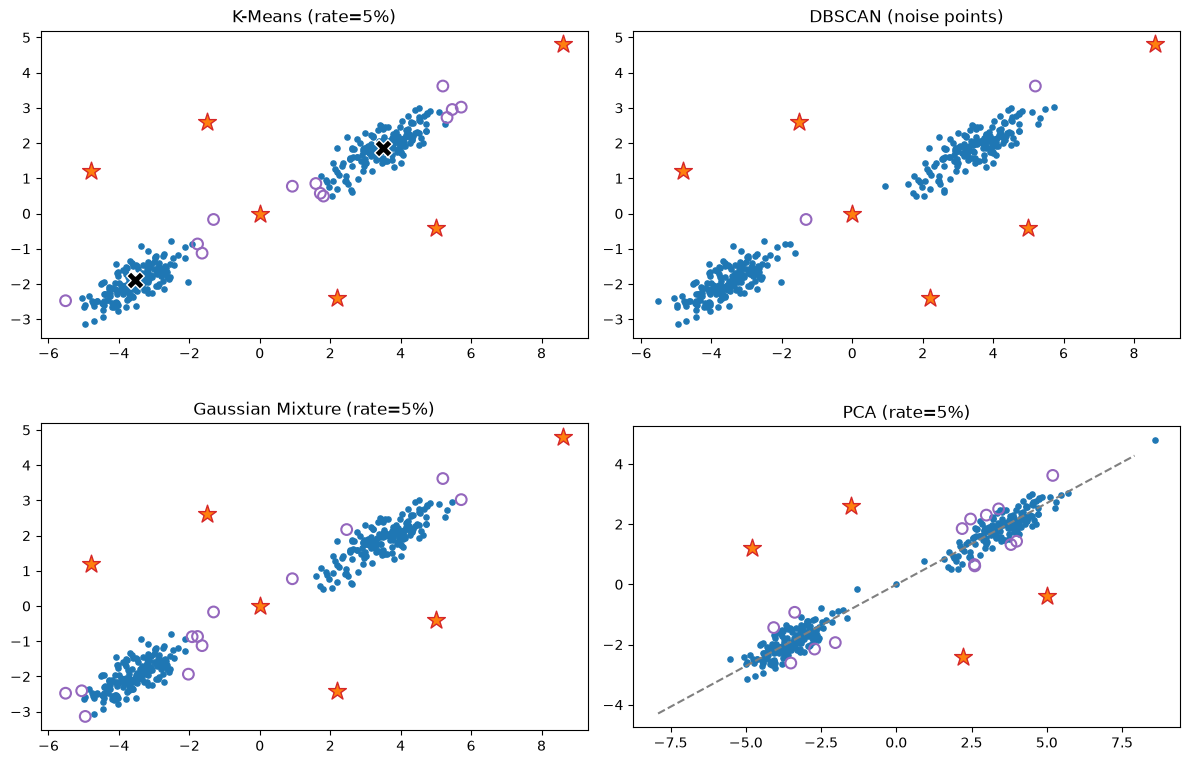

In [5]:
results_05 = {
    "K-Means (rate=5%)": kmeans_flags,
    "DBSCAN (noise points)": dbscan_flags,
    "Gaussian Mixture (rate=5%)": gmm_flags,
    "PCA (rate=5%)": pca_flags,
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (title, flags) in zip(axes.ravel(), results_05.items()):
    ax.scatter(*X_anom[~flags].T, s=14, color="tab:blue")
    ax.scatter(*X_anom[flags & ~is_planted].T, s=60, marker="o", facecolors="none", edgecolor="tab:purple", linewidths=1.5, label="flagged normal")
    ax.scatter(*X_anom[flags & is_planted].T, s=180, marker="*", color="tab:orange", edgecolor="tab:red", zorder=3, label="planted anomaly")
    ax.set_title(title)
    ax.set_aspect("equal")

axes[0, 0].scatter(*kmeans_anom.cluster_centers_.T, s=160, marker="X", c="black", edgecolor="white")
line = pca_anom.mean_ + np.outer([-9, 9], pca_anom.components_[0])
axes[1, 1].plot(*line.T, "--", color="gray")
plt.tight_layout()
plt.show()

# Final Answer

Which tools start flagging normal points when the threshold rate is changed to 0.05 (5%)?

- K-Means: Flags 12 normal points as anomalies.
- Gaussian Mixture Model (GMM): Flags 12 normal points as anomalies.
- PCA: Flags 14 normal points as anomalies.
- DBSCAN: Flags 2 normal points as noise.

## Why?

K-Means, GMM, and PCA use the top 5% of their anomaly scores to identify unusual observations. Increasing the threshold rate can cause more observations to be flagged, including some normal points.

DBSCAN works differently. It does not use a percentage-based threshold. Instead, it identifies noise based on local density, controlled by parameters such as eps and min_samples.

With the current settings, DBSCAN flags 8 observations as noise, including 2 normal points and all 6 planted anomalies.

These results show that different anomaly-detection methods identify unusual observations in different ways. Increasing the threshold rate can also increase false positives.